<a href="https://colab.research.google.com/github/Samuel-1302/Teste-de-software/blob/main/MKD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Bloco 1

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df_mkd = pd.read_csv("/content/digital_marketing_campaign_dataset.csv")

#Bloco 2
## Descrição das Variáveis + Tipos de Dados

In [ ]:
df_mkd.head()

,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1
2,8002,46,Female,88456,PPC,Awareness,1546.429596,0.277490,0.076423,2,8.223619,13.794901,0,11,2,8,2337,IsConfid,ToolConfid,1
3,8003,32,Female,44085,PPC,Conversion,539.525936,0.137611,0.088004,47,4.540939,14.688363,89,2,2,0,2463,IsConfid,ToolConfid,1
4,8004,60,Female,83964,PPC,Conversion,1678.043573,0.252851,0.109940,0,2.046847,13.993370,6,6,6,8,4345,IsConfid,ToolConfid,1


In [ ]:
df_mkd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CustomerID           8000 non-null   int64  
 1   Age                  8000 non-null   int64  
 2   Gender               8000 non-null   object 
 3   Income               8000 non-null   int64  
 4   CampaignChannel      8000 non-null   object 
 5   CampaignType         8000 non-null   object 
 6   AdSpend              8000 non-null   float64
 7   ClickThroughRate     8000 non-null   float64
 8   ConversionRate       8000 non-null   float64
 9   WebsiteVisits        8000 non-null   int64  
 10  PagesPerVisit        8000 non-null   float64
 11  TimeOnSite           8000 non-null   float64
 12  SocialShares         8000 non-null   int64  
 13  EmailOpens           8000 non-null   int64  
 14  EmailClicks          8000 non-null   int64  
 15  PreviousPurchases    8000 non-null   i

Texto do Bloco 2 — Descrição das Variáveis + Tipos de Dados
A base possui 8.000 registros e 20 colunas, sem nenhum valor ausente (todas as colunas com 8.000 non-null). Cada linha representa um cliente exposto a campanhas de marketing digital. As variáveis se dividem em: dados demográficos (Age, Gender, Income), variáveis de marketing (CampaignChannel, CampaignType, AdSpend, ClickThroughRate, ConversionRate, AdvertisingPlatform, AdvertisingTool), engajamento do cliente (WebsiteVisits, PagesPerVisit, TimeOnSite, SocialShares, EmailOpens, EmailClicks) e histórico (PreviousPurchases, LoyaltyPoints). Quanto aos tipos, temos 5 colunas float64, 10 int64 e 5 object (texto/categóricas), ou seja, a base mistura dados numéricos e categóricos — diferente de bases totalmente numéricas. A variável-alvo é Conversion (0 = não converteu, 1 = converteu). A coluna CustomerID é apenas um identificador e não entra na análise.

#Bloco 3
##Dados Ausentes + Duplicatas + Outliers

In [ ]:
df_mkd.isnull().sum()


,0
CustomerID,0
Age,0
Gender,0
Income,0
CampaignChannel,0
CampaignType,0
AdSpend,0
ClickThroughRate,0
ConversionRate,0
WebsiteVisits,0


In [ ]:
(df_mkd.isnull().sum() / len(df_mkd)) * 100

,0
CustomerID,0.0
Age,0.0
Gender,0.0
Income,0.0
CampaignChannel,0.0
CampaignType,0.0
AdSpend,0.0
ClickThroughRate,0.0
ConversionRate,0.0
WebsiteVisits,0.0


In [ ]:
print(df_mkd.duplicated().sum())


0


In [ ]:
categoricas = df_mkd.select_dtypes(include='object')
for coluna in categoricas.columns:
    print(f"Coluna '{coluna}':")
    print(df_mkd[coluna].unique())
    print()


Coluna 'Gender':
['Female' 'Male']

Coluna 'CampaignChannel':
['Social Media' 'Email' 'PPC' 'Referral' 'SEO']

Coluna 'CampaignType':
['Awareness' 'Retention' 'Conversion' 'Consideration']

Coluna 'AdvertisingPlatform':
['IsConfid']

Coluna 'AdvertisingTool':
['ToolConfid']



In [ ]:
df_mkd = df_mkd.drop(columns=['AdvertisingPlatform', 'AdvertisingTool'])

In [ ]:
print(df_mkd.shape)
df_mkd.info()

(8000, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         8000 non-null   int64  
 1   Age                8000 non-null   int64  
 2   Gender             8000 non-null   object 
 3   Income             8000 non-null   int64  
 4   CampaignChannel    8000 non-null   object 
 5   CampaignType       8000 non-null   object 
 6   AdSpend            8000 non-null   float64
 7   ClickThroughRate   8000 non-null   float64
 8   ConversionRate     8000 non-null   float64
 9   WebsiteVisits      8000 non-null   int64  
 10  PagesPerVisit      8000 non-null   float64
 11  TimeOnSite         8000 non-null   float64
 12  SocialShares       8000 non-null   int64  
 13  EmailOpens         8000 non-null   int64  
 14  EmailClicks        8000 non-null   int64  
 15  PreviousPurchases  8000 non-null   int64  
 16  LoyaltyPoints

In [ ]:
numericas = df_mkd.select_dtypes(include='number').drop(columns=['CustomerID', 'Conversion'])

for coluna in numericas.columns:
    Q1 = df_mkd[coluna].quantile(0.25)
    Q3 = df_mkd[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    outliers = df_mkd[(df_mkd[coluna] < limite_inferior) | (df_mkd[coluna] > limite_superior)]
    print(f"{coluna}: {len(outliers)} outliers")


Age: 0 outliers
Income: 0 outliers
AdSpend: 0 outliers
ClickThroughRate: 0 outliers
ConversionRate: 0 outliers
WebsiteVisits: 0 outliers
PagesPerVisit: 0 outliers
TimeOnSite: 0 outliers
SocialShares: 0 outliers
EmailOpens: 0 outliers
EmailClicks: 0 outliers
PreviousPurchases: 0 outliers
LoyaltyPoints: 0 outliers


Verificamos a integridade da base: nenhum dado ausente, nenhuma linha duplicada e nenhum outlier (método IQR) — tudo zero. Nas variáveis categóricas, as categorias estão consistentes (ex.: Gender só "Female"/"Male"). Identificamos que AdvertisingPlatform e AdvertisingTool tinham um único valor em todas as linhas (colunas confidenciais e constantes); como não trazem informação útil, foram removidas, reduzindo a base de 20 para 18 colunas. Resultado: base íntegra e pronta para as análises seguintes.

#Bloco 4
##Estatísticas descritivas

In [ ]:
print(df_mkd.describe()
)

        CustomerID          Age         Income      AdSpend  ClickThroughRate  \
count   8000.00000  8000.000000    8000.000000  8000.000000       8000.000000   
mean   11999.50000    43.625500   84664.196750  5000.944830          0.154829   
std     2309.54541    14.902785   37580.387945  2838.038153          0.084007   
min     8000.00000    18.000000   20014.000000   100.054813          0.010005   
25%     9999.75000    31.000000   51744.500000  2523.221165          0.082635   
50%    11999.50000    43.000000   84926.500000  5013.440044          0.154505   
75%    13999.25000    56.000000  116815.750000  7407.989369          0.228207   
max    15999.00000    69.000000  149986.000000  9997.914781          0.299968   

       ConversionRate  WebsiteVisits  PagesPerVisit   TimeOnSite  \
count     8000.000000    8000.000000    8000.000000  8000.000000   
mean         0.104389      24.751625       5.549299     7.727718   
std          0.054878      14.312269       2.607358     4.228218  

O describe() mostrou que as variáveis numéricas têm faixas realistas e equilibradas, com médias próximas das medianas (ex.: AdSpend com média e mediana em torno de 5.000), indicando distribuições simétricas e sem valores distorcidos — o que reforça a ausência de outliers vista no Bloco 3. Age varia de 18 a 69 anos e Income de ~20 mil a ~150 mil USD. O principal achado está na variável-alvo Conversion: sua média de 0,88 revela que cerca de 88% dos clientes converteram e apenas ~12% não converteram, evidenciando um desbalanceamento de classes (a classe rara aqui é o "não converteu"), ponto que será analisado no bloco da variável-alvo e tratado na modelagem.

#Bloco 5
##Distribuição das principais variáveis

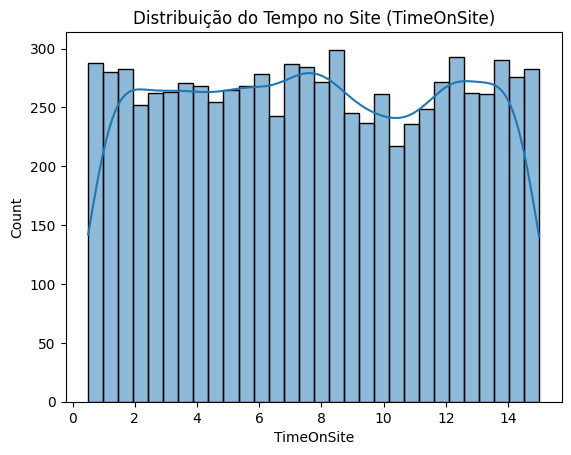

In [ ]:
sns.histplot(data=df_mkd, x='TimeOnSite', kde=True, bins=30)
plt.title('Distribuição do Tempo no Site (TimeOnSite)')
plt.show()


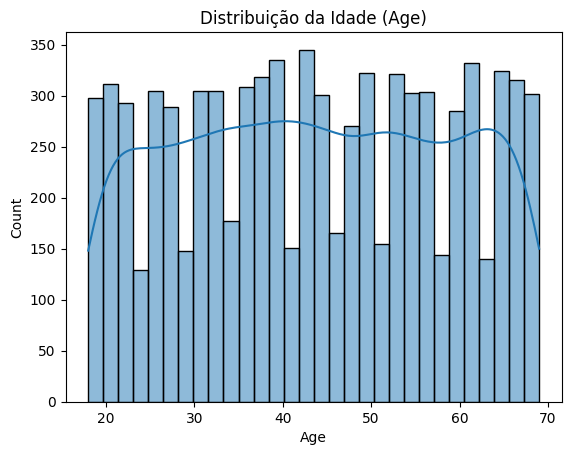

In [ ]:
sns.histplot(data=df_mkd, x='Age', kde=True, bins=30)
plt.title('Distribuição da Idade (Age)')
plt.show()


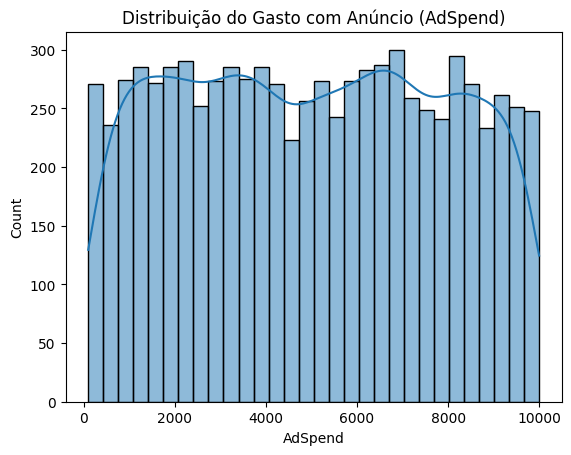

In [ ]:
sns.histplot(data=df_mkd, x='AdSpend', kde=True, bins=30)
plt.title('Distribuição do Gasto com Anúncio (AdSpend)')
plt.show()


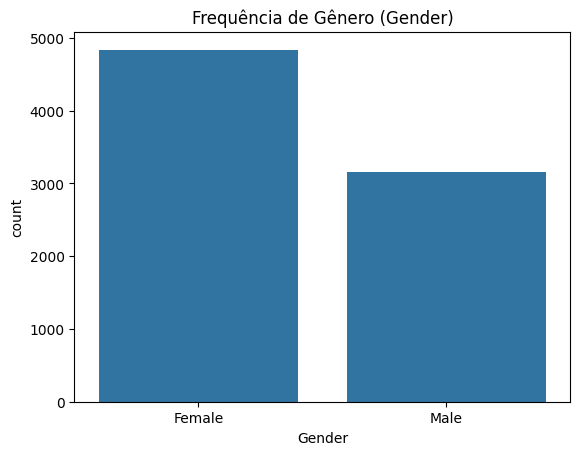

In [ ]:
sns.countplot(data=df_mkd, x='Gender')
plt.title('Frequência de Gênero (Gender)')
plt.show()


In [ ]:
df_mkd['CampaignChannel'].value_counts(normalize=True) * 100


,proportion
CampaignChannel,
Referral,21.4875
PPC,20.6875
Email,19.4625
SEO,19.3750
Social Media,18.9875


As variáveis numéricas (Age, AdSpend, TimeOnSite) apresentam distribuição aproximadamente uniforme, sem concentração em faixas específicas nem valores extremos — comportamento coerente com a natureza sintética da base e com a ausência de outliers vista no Bloco 3. Entre as categóricas, Gender mostra predominância feminina (~60% Female contra ~40% Male), enquanto CampaignChannel está bem distribuído entre os cinco canais (cada um com ~19% a 21%), indicando que nenhum canal domina a base.

#Bloco 6
##Análise da principal variável + identificação de desbalanceamento

In [ ]:
print(df_mkd['Conversion'].value_counts(normalize=True) * 100)


Conversion
1    87.65
0    12.35
Name: proportion, dtype: float64


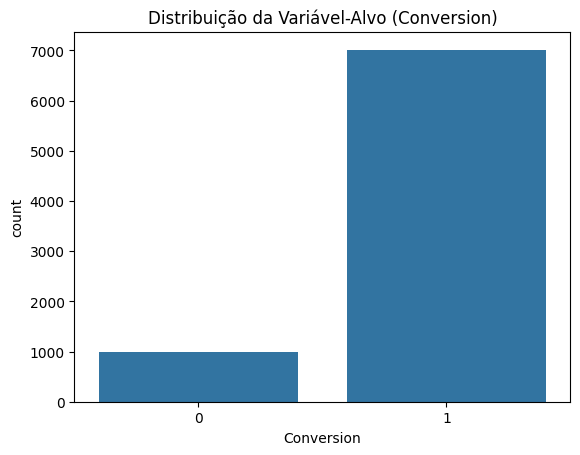

In [ ]:
sns.countplot(data=df_mkd, x='Conversion')
plt.title('Distribuição da Variável-Alvo (Conversion)')
plt.show()


A variável-alvo Conversion está desbalanceada: 87,65% dos clientes converteram (classe 1) e apenas 12,35% não converteram (classe 0). Ou seja, a classe rara aqui é o "não converteu" — o oposto da maioria dos problemas de fraude, onde o evento raro é o positivo. Esse desbalanceamento é relevante porque um modelo que simplesmente "chutasse sempre conversão" já acertaria ~88%, o que torna a acurácia uma métrica enganosa. Por isso, na modelagem (Etapa 2), será importante usar métricas como recall, precisão e F1 voltadas à classe minoritária (não converteu) e considerar técnicas de balanceamento, para que o modelo realmente aprenda a identificar quem NÃO converte.

#Bloco 7
##Análise de relações e correlações entre variáveis

In [ ]:
df_mkd.corr(numeric_only=True)['Conversion']

,Conversion
CustomerID,-0.180742
Age,0.001606
Income,0.013974
AdSpend,0.124672
ClickThroughRate,0.120012
ConversionRate,0.093185
WebsiteVisits,0.079339
PagesPerVisit,0.102840
TimeOnSite,0.129609
SocialShares,-0.011449


In [ ]:
numericas = df_mkd.select_dtypes(include='number').drop(columns=['CustomerID'])
numericas.corr()['Conversion'].sort_values(ascending=False)


,Conversion
Conversion,1.000000
TimeOnSite,0.129609
EmailClicks,0.129521
EmailOpens,0.124884
AdSpend,0.124672
ClickThroughRate,0.120012
PreviousPurchases,0.111781
PagesPerVisit,0.102840
LoyaltyPoints,0.095004
ConversionRate,0.093185


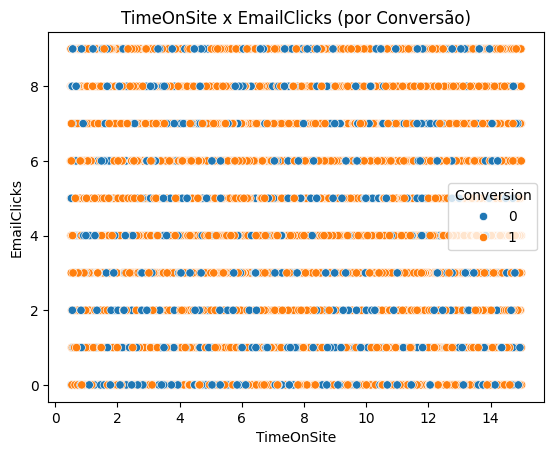

In [ ]:
sns.scatterplot(data=df_mkd, x='TimeOnSite', y='EmailClicks', hue='Conversion')
plt.title('TimeOnSite x EmailClicks (por Conversão)')
plt.show()


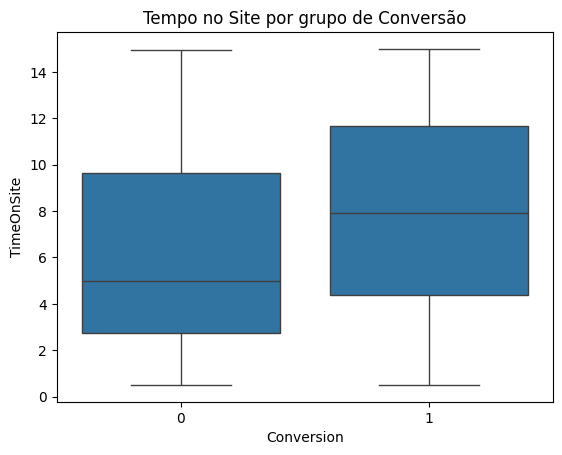

In [ ]:
sns.boxplot(data=df_mkd, x='Conversion', y='TimeOnSite')
plt.title('Tempo no Site por grupo de Conversão')
plt.show()


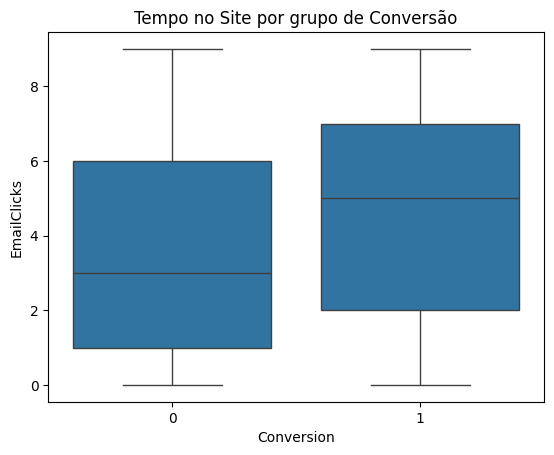

In [ ]:
sns.boxplot(data=df_mkd, x='Conversion', y='EmailClicks')
plt.title('Tempo no Site por grupo de Conversão')
plt.show()

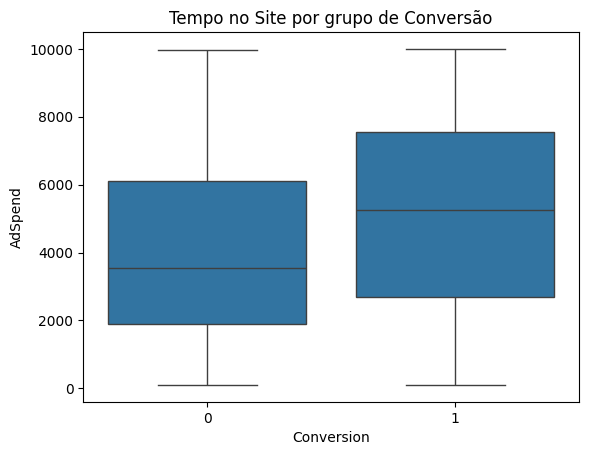

In [ ]:
 sns.boxplot(data=df_mkd, x='Conversion', y='AdSpend')
plt.title('Tempo no Site por grupo de Conversão')
plt.show()

In [ ]:
df_mkd.groupby('CampaignType')['Conversion'].mean().sort_values(ascending=False)

,Conversion
CampaignType,
Conversion,0.933558
Retention,0.858243
Consideration,0.855634
Awareness,0.855634


In [ ]:
df_mkd.groupby('CampaignChannel')['Conversion'].mean().sort_values(ascending=False)

,Conversion
CampaignChannel,
Referral,0.883072
PPC,0.882779
SEO,0.876774
Email,0.870263
Social Media,0.868334


In [ ]:
df_mkd.groupby('Gender')['Conversion'].mean().sort_values(ascending=False)

,Conversion
Gender,
Male,0.876938
Female,0.876214


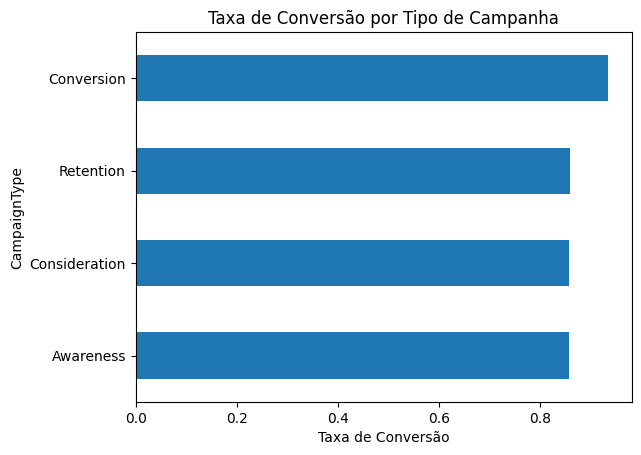

In [ ]:
df_mkd.groupby('CampaignType')['Conversion'].mean().sort_values().plot(kind='barh')
plt.title('Taxa de Conversão por Tipo de Campanha')
plt.xlabel('Taxa de Conversão')
plt.show()

As correlações numéricas com a Conversion são todas fracas; as maiores são TimeOnSite, EmailClicks, EmailOpens e AdSpend (todas ~0,12–0,13), e os boxplots confirmam que quem converte tende a se engajar um pouco mais, mas com muita sobreposição entre os grupos. Já nas variáveis categóricas, o tipo de campanha faz diferença: campanhas do tipo "Conversion" convertem 93,4%, contra ~85% das demais. Em contrapartida, o canal da campanha (diferença de ~1,5 pp) e o gênero (diferença de ~0,07 pp) praticamente não afetam a conversão. Conclusão do bloco: a conversão depende mais do engajamento do cliente e do tipo de campanha do que de características demográficas ou do canal utilizado.